# 현실의 데이터 34: 야구: 오늘 경기, 홈팀이 이길까?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/34_baseball.ipynb)

**분야**: 스포츠 · 게임 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 데이터 야구 (세이버메트릭스) · 승패 예측 · 피타고리안 승률

> 메이저리그 10시즌, 2만 4천 경기. 경기 전 성적만 보고 오늘 승패를 맞힐 수 있을까?

**데이터**: Retrosheet 경기 기록 (MLB 2015 ~ 2025) (약 5MB (시즌 10개)). Retrosheet 이 공개한 메이저리그 경기별 기록: 날짜 · 두 팀 · 점수 · 낮/밤 · 구장 · 관중 · 경기 시간 · 선발 투수. 2020 단축 시즌은 뺐다. The information used here was obtained free of charge from and is copyrighted by Retrosheet. Interested parties may contact Retrosheet at www.retrosheet.org..

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 경기 하나 |
| ② 입력 X | 두 팀의 그 경기 전까지 승률 · 경기당 득실차 · 최근 10경기 승률 |
| ③ 출력 y | 홈팀이 이기나 (확률) |
| ④ 평가지표 | 정확도, 로그 손실 |
| ⑤ 기준선 | 늘 홈팀 승 (약 53%) |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Miller (2007) A Derivation of the Pythagorean Won-Loss Formula in Baseball, Chance](https://arxiv.org/abs/math/0509698)
- [Retrosheet: 경기 기록 (game logs) 칸 설명](https://www.retrosheet.org/gamelogs/glfields.txt)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

시즌마다 zip 파일 하나 (0.5MB). 머리줄이 없는 161칸짜리 표라서 필요한 칸만 번호로 골라 이름을 붙인다 (칸 설명: retrosheet.org/gamelogs/glfields.txt).

출처 문구 (Retrosheet 의 조건): *The information used here was obtained free of charge from and is copyrighted by Retrosheet. Interested parties may contact Retrosheet at www.retrosheet.org.*

In [2]:
SEASONS = [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025]      # 2020 was a 60-game season
FIELDS = {0: "date", 3: "away", 6: "home", 9: "away_runs", 10: "home_runs", 12: "day_night", 16: "park", 17: "attendance", 18: "minutes"}

def read_season(year):
    """One season of Retrosheet game logs with the columns in FIELDS"""
    path = download(f"https://www.retrosheet.org/gamelogs/gl{year}.zip", f"data/retrosheet/gl{year}.zip")
    with zipfile.ZipFile(path) as z:
        return pd.read_csv(z.open(z.namelist()[0]), header=None, usecols=list(FIELDS)).rename(columns=FIELDS)

games = pd.concat([read_season(y) for y in SEASONS], ignore_index=True)
games["date"] = pd.to_datetime(games["date"].astype(str)); games["season"] = games["date"].dt.year
games = games[games["home_runs"] != games["away_runs"]].reset_index(drop=True)     # drop the rare tied (suspended) games
games["home_win"] = (games["home_runs"] > games["away_runs"]).astype(int)
print(games.shape, "| teams", games["home"].nunique(), "| home team won", f"{games['home_win'].mean():.1%}")
games.sample(5, random_state=0)

(24294, 11) | teams 31 | home team won 53.3%


,date,away,home,away_runs,home_runs,day_night,park,attendance,minutes,season,home_win
10576,2019-06-01,SFN,BAL,8,2,D,BAL12,19352.0,168,2019,0
22245,2025-04-25,MIL,SLN,2,3,N,STL10,24437.0,149,2025,1
7473,2018-04-13,ARI,LAN,8,7,N,LOS03,43791.0,210,2018,0
19195,2023-09-14,MIA,MIL,2,4,D,MIL06,26529.0,153,2023,1
19271,2023-09-19,CLE,KCA,6,7,N,KAN06,15254.0,180,2023,1


## 열어 보기: 홈 이점과 '득실차'

- 시즌마다 홈팀은 몇 % 이겼을까?
- 한 시즌 동안 낸 점수 (득점) 와 내준 점수 (실점) 만으로 승률을 맞힐 수 있을까? 빌 제임스의 **피타고리안 승률** = 득점² / (득점² + 실점²).

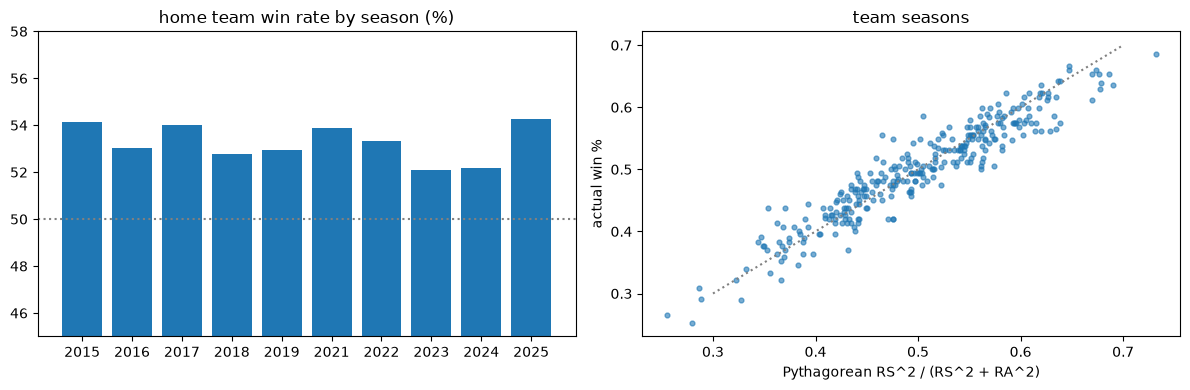

team-season win % vs Pythagorean: correlation 0.946, MAE 3.5 wins per 162 games


In [3]:
def team_seasons(games):
    """One row per team and season: games, wins, runs scored and allowed"""
    home = games.rename(columns={"home": "team", "home_runs": "rs", "away_runs": "ra"}).assign(win=games["home_win"])
    away = games.rename(columns={"away": "team", "away_runs": "rs", "home_runs": "ra"}).assign(win=1 - games["home_win"])
    both = pd.concat([home[["season", "team", "rs", "ra", "win"]], away[["season", "team", "rs", "ra", "win"]]])
    out = both.groupby(["season", "team"]).agg(g=("win", "size"), w=("win", "sum"), rs=("rs", "sum"), ra=("ra", "sum")).reset_index()
    out["wpct"] = out["w"] / out["g"]; out["pythag"] = out["rs"] ** 2 / (out["rs"] ** 2 + out["ra"] ** 2)
    return out

ts = team_seasons(games)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
by_season = games.groupby("season")["home_win"].mean() * 100
axs[0].bar(by_season.index.astype(str), by_season.values, color="tab:blue"); axs[0].axhline(50, color="gray", ls=":")
axs[0].set_ylim(45, 58); axs[0].set_title("home team win rate by season (%)")
axs[1].scatter(ts["pythag"], ts["wpct"], s=12, alpha=0.6); axs[1].plot([0.3, 0.7], [0.3, 0.7], color="gray", ls=":")
axs[1].set_xlabel("Pythagorean RS^2 / (RS^2 + RA^2)"); axs[1].set_ylabel("actual win %"); axs[1].set_title("team seasons")
plt.tight_layout(); plt.show()
print(f"team-season win % vs Pythagorean: correlation {ts['wpct'].corr(ts['pythag']):.3f}, MAE {np.mean(np.abs(ts['wpct'] - ts['pythag'])) * 162:.1f} wins per 162 games")

## 문제 하나 골라 보기: 경기 전 성적 → 오늘 홈팀 승리

**함정 조심**: 입력은 그 경기 **전까지** 의 성적만 써야 한다. 시즌 최종 승률을 쓰면 오늘 경기 결과가 이미 들어 있다 (데이터 누수, 1주 3차시). 그래서 팀마다 날짜 순으로 줄 세우고 한 칸 밀어서 (`shift`) 누적 평균을 낸다.

**시간 순서**: 2015 ~ 2023 학습, 2024 · 2025 시험. 시즌 첫 10경기는 성적이 너무 적어 뺀다.
- 기준선 1: 늘 홈팀 승
- 기준선 2: 지금까지 승률이 높은 팀 승
- 모델: 두 팀의 차이 (승률 · 경기당 득실차 · 최근 10경기 승률) → 로지스틱 회귀

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

def form_before_game(games):
    """For every game, home-minus-away form computed only from earlier games of the same season"""
    home = pd.DataFrame({"gid": games.index, "season": games["season"], "team": games["home"], "rd": games["home_runs"] - games["away_runs"], "win": games["home_win"], "is_home": 1})
    away = pd.DataFrame({"gid": games.index, "season": games["season"], "team": games["away"], "rd": games["away_runs"] - games["home_runs"], "win": 1 - games["home_win"], "is_home": 0})
    t = pd.concat([home, away]).sort_values(["season", "team", "gid"]); grp = t.groupby(["season", "team"])
    t["n"] = grp.cumcount()                                                   # games already played
    t["wpct"] = grp["win"].transform(lambda s: s.shift().expanding().mean())
    t["rd_pg"] = grp["rd"].transform(lambda s: s.shift().expanding().mean())
    t["last10"] = grp["win"].transform(lambda s: s.shift().rolling(10, min_periods=1).mean())
    h = t[t["is_home"] == 1].set_index("gid").reindex(games.index); a = t[t["is_home"] == 0].set_index("gid").reindex(games.index)
    X = pd.DataFrame({"season": games["season"], "home_win": games["home_win"], "n": np.minimum(h["n"], a["n"])})
    for c in ["wpct", "rd_pg", "last10"]:
        X["d_" + c] = h[c] - a[c]
    return X[X["n"] >= 10].dropna()

X = form_before_game(games)
tr, te = X[X["season"] <= 2023], X[X["season"] >= 2024]; y = te["home_win"].values
print(f"train {len(tr):,} games | test {len(te):,} games")
print(f"{'always home':30s} accuracy {np.mean(y == 1):.1%}   log loss {log_loss(y, np.full(len(y), tr['home_win'].mean())):.4f}")
print(f"{'better record so far':30s} accuracy {np.mean((te['d_wpct'] > 0).astype(int).values == y):.1%}")
for feats in [["d_wpct"], ["d_wpct", "d_rd_pg"], ["d_wpct", "d_rd_pg", "d_last10"]]:
    p = LogisticRegression().fit(tr[feats], tr["home_win"]).predict_proba(te[feats])[:, 1]
    print(f"{' + '.join(feats):30s} accuracy {np.mean((p > 0.5) == y):.1%}   log loss {log_loss(y, p):.4f}")

train 18,185 games | test 4,547 games
always home                    accuracy 53.2%   log loss 0.6912
better record so far           accuracy 54.0%
d_wpct                         accuracy 55.0%   log loss 0.6841
d_wpct + d_rd_pg               accuracy 55.4%   log loss 0.6827
d_wpct + d_rd_pg + d_last10    accuracy 55.6%   log loss 0.6827


**관찰**: 늘 홈팀이라고만 해도 53% 를 맞힌다. 경기 전 성적을 다 써도 55% 쯤이다. 야구는 원래 잘 맞히기 어려운 경기다 (아무리 강한 팀도 한 시즌에 60% 를 넘기기 어렵다). 승률보다 **득실차** 가 조금 더 도움이 되고 (운이 덜 섞인 실력), **최근 10경기 (연승 · 연패의 '기세')** 는 거의 보탬이 안 된다. 정확도 2% 차이는 작아 보이지만, 확률을 묻는 문제라면 로그 손실로 재야 그 차이가 제대로 보인다.

## 다른 문제로 바꿔 보기

- **선발 투수**: 오늘 누가 던지나 (`FIELDS` 에 101 · 103 번 칸, 선발 투수 ID 를 더한다). 투수의 지난 등판 성적을 입력에 넣으면 얼마나 오를까?
- **관중 수 예측 (회귀)**: 한 행 = 경기, 출력 = 관중 수. 요일 · 낮/밤 · 두 팀 성적 · 구장. 구단 마케팅 · 티켓 가격 문제다.
- **경기 시간 예측**: `minutes` 열. 2023년 피치 클록 도입 뒤 경기가 얼마나 짧아졌을까? (규칙 변경 = 데이터 분포가 바뀌는 순간)
- **KBO 로**: 한국 프로야구 기록은 KBO 기록실 (koreabaseball.com) 에 있다. 같은 다섯 칸으로 문제를 다시 세워 보자.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |